### Data Loading and Initial Inspection

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats
import statsmodels.formula.api as smf
import warnings
warnings.filterwarnings('ignore')

# Agoda colors hex codes
NAVY="#10239E"; BLUE="#2B5CE6"; BRIGHT="#4F7DF9"; LIGHT="#B5D4F4"
MAGENTA="#E5326E"; ORANGE="#FF9900"; INK="#1C2233"; MUT="#64748B"

file_path = '/content/Case_Study_Urgency_Message_Data.xlsx'

# Read all sheets and combine them
xls = pd.ExcelFile(file_path)
sheet_names = xls.sheet_names

print(f"Sheets found in the Excel file: {sheet_names}")

all_dfs = []
for sheet_name in sheet_names:
    df_sheet = pd.read_excel(file_path, sheet_name=sheet_name)
    df_sheet['city_name'] = sheet_name
    all_dfs.append(df_sheet)

df_combined = pd.concat(all_dfs, ignore_index=True)
df = df_combined

print(f"\nCombined DataFrame shape: {df.shape}")
print('\nFirst 5 rows of the combined DataFrame:')
display(df.head())

print('\nDataFrame Info for combined data:')
df.info()

print('\nInitial missing values:')
print(df.isnull().sum())

Sheets found in the Excel file: ['City_A', 'City_B', 'City_C', 'City_D', 'City_E']

Combined DataFrame shape: (49064, 12)

First 5 rows of the combined DataFrame:


,#,ADR_USD,hotel_id,city_id,star_rating,accommadation_type_name,chain_hotel,booking_date,checkin_date,checkout_date,city_name,accommodation_type_name
0,1,71.06,297388,9395,2.5,Hotel,non-chain,2016-08-02,2016-10-01,2016-10-02,City_A,NaN
1,2,76.56,298322,9395,3.0,Hotel,non-chain,2016-08-02,2016-10-01,2016-10-02,City_A,NaN
2,3,153.88,2313076,9395,5.0,Hotel,chain,2016-08-02,2016-10-01,2016-10-02,City_A,NaN
3,4,126.60,2240838,9395,3.5,Hotel,non-chain,2016-08-04,2016-10-02,2016-10-03,City_A,NaN
4,5,115.08,2240838,9395,3.5,Hotel,non-chain,2016-08-04,2016-10-02,2016-10-03,City_A,NaN



DataFrame Info for combined data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49064 entries, 0 to 49063
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   #                        49064 non-null  int64         
 1   ADR_USD                  49064 non-null  float64       
 2   hotel_id                 49064 non-null  int64         
 3   city_id                  49064 non-null  int64         
 4   star_rating              49064 non-null  float64       
 5   accommadation_type_name  27298 non-null  object        
 6   chain_hotel              49064 non-null  object        
 7   booking_date             49064 non-null  datetime64[ns]
 8   checkin_date             49064 non-null  datetime64[ns]
 9   checkout_date            49064 non-null  datetime64[ns]
 10  city_name                49064 non-null  object        
 11  accommodation_type_name  21766 non-null  object        
dt

### Data Cleaning: Handling Accommodation Type and Creating Booking Window

In [ ]:
print('Unique values in `accommadation_type_name`:')
print(df['accommadation_type_name'].unique())

print('\nUnique values in `accommodation_type_name`:')
print(df['accommodation_type_name'].unique())

df['accommodation_type'] = df['accommadation_type_name'].fillna(df['accommodation_type_name'])
df.drop(columns=['accommadation_type_name', 'accommodation_type_name'], inplace=True)

print('\nDataFrame Info after cleaning accommodation type columns:')
df.info()

print('\nMissing values in `accommodation_type` after cleaning:')
print(df['accommodation_type'].isnull().sum())

Unique values in `accommadation_type_name`:
['Hotel' 'Serviced Apartment' 'Hostel' 'Guest House / Bed & Breakfast'
 'Motel' 'Apartment' 'Resort' 'Ryokan' 'Resort Villa' 'Private Villa'
 'Bungalow' 'Villa' 'Holiday Park / Caravan Park' nan]

Unique values in `accommodation_type_name`:
[nan 'Hotel' 'Guest House / Bed & Breakfast' 'Resort' 'Ryokan'
 'Capsule Hotel' 'Hostel' 'Apartment' 'Serviced Apartment' 'Love Hotel'
 'Home' 'Resort Villa' 'Private Villa' 'Bungalow']

DataFrame Info after cleaning accommodation type columns:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49064 entries, 0 to 49063
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   #                   49064 non-null  int64         
 1   ADR_USD             49064 non-null  float64       
 2   hotel_id            49064 non-null  int64         
 3   city_id             49064 non-null  int64         
 4   star_rating         

### Feature Engineering: Booking Window and Additional Features

In [ ]:
df['booking_window'] = (df['checkin_date'] - df['booking_date']).dt.days
df = df[df['booking_window'] >= 0] # Remove invalid booking windows

# Create additional features
df['weekend'] = df['checkin_date'].dt.dayofweek.isin([4, 5]).astype(int)
df['month'] = df['checkin_date'].dt.month
df['los'] = (df['checkout_date'] - df['checkin_date']).dt.days
df['chain'] = (df['chain_hotel'].astype(str).str.lower() == 'chain').astype(int)
df['stay_id'] = df['hotel_id'].astype(str) + '_' + df['checkin_date'].astype(str)
df['adr'] = df['ADR_USD']

print('\nDescriptive statistics of numerical columns after cleaning and feature creation:')
display(df.describe())

print('\nFinal check for missing values:')
print(df.isnull().sum())

print(f"\nWeekend bookings: {df['weekend'].sum():,} ({df['weekend'].mean()*100:.1f}%)")
print(f"Chain hotels: {df['chain'].sum():,}  ({df['chain'].mean()*100:.1f}%)")
print(f"Unique stay IDs: {df['stay_id'].nunique():,}")
print(f"Avg length of stay: {df['los'].mean():.2f} days")


Descriptive statistics of numerical columns after cleaning and feature creation:


,#,ADR_USD,hotel_id,city_id,star_rating,booking_date,checkin_date,checkout_date,booking_window,weekend,month,los,chain,adr
count,49061.000000,49061.000000,4.906100e+04,49061.000000,49061.000000,49061,49061,49061,49061.000000,49061.000000,49061.000000,49061.000000,49061.000000,49061.000000
mean,7103.853427,148.093018,7.920654e+05,11036.150343,3.328948,2016-11-01 22:25:50.477976576,2016-11-16 11:09:38.879354368,2016-11-18 03:23:33.040908288,14.530421,0.379833,11.026314,1.676321,0.269787,148.093018
min,1.000000,4.260000,7.700000e+02,5085.000000,0.000000,2016-08-02 00:00:00,2016-10-01 00:00:00,2016-10-02 00:00:00,0.000000,0.000000,10.000000,1.000000,0.000000,4.260000
25%,2454.000000,62.560000,1.979960e+05,9395.000000,3.000000,2016-10-10 00:00:00,2016-10-23 00:00:00,2016-10-25 00:00:00,2.000000,0.000000,10.000000,1.000000,0.000000,62.560000
50%,4929.000000,113.660000,5.260860e+05,9395.000000,3.500000,2016-11-02 00:00:00,2016-11-17 00:00:00,2016-11-19 00:00:00,8.000000,0.000000,11.000000,1.000000,0.000000,113.660000
75%,10126.000000,192.220000,1.249476e+06,16808.000000,4.000000,2016-11-26 00:00:00,2016-12-10 00:00:00,2016-12-12 00:00:00,23.000000,1.000000,12.000000,2.000000,1.000000,192.220000
max,22366.000000,3156.860000,5.211366e+06,17193.000000,5.000000,2016-12-31 00:00:00,2016-12-31 00:00:00,2017-01-03 00:00:00,60.000000,1.000000,12.000000,3.000000,1.000000,3156.860000
std,6030.973177,135.341195,7.559238e+05,4174.829299,0.994651,NaN,NaN,NaN,15.680657,0.485350,0.828914,0.772224,0.443853,135.341195



Final check for missing values:
#                     0
ADR_USD               0
hotel_id              0
city_id               0
star_rating           0
chain_hotel           0
booking_date          0
checkin_date          0
checkout_date         0
city_name             0
accommodation_type    0
booking_window        0
weekend               0
month                 0
los                   0
chain                 0
stay_id               0
adr                   0
dtype: int64

Weekend bookings: 18,635 (38.0%)
Chain hotels: 13,236  (27.0%)
Unique stay IDs: 18,729
Avg length of stay: 1.68 days


### Price Trend Visualization

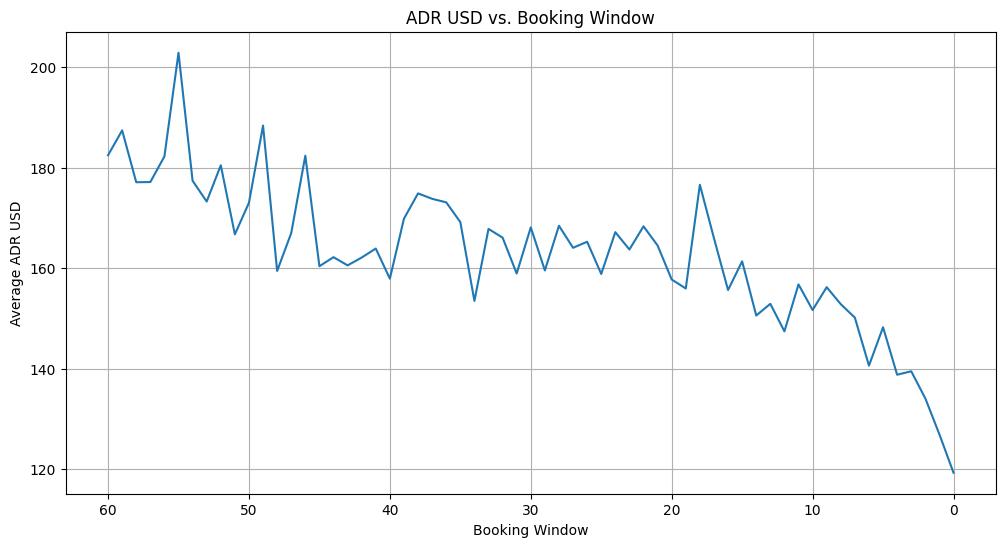

In [ ]:
price_trend = df.groupby('booking_window')['ADR_USD'].mean().reset_index()

plt.figure(figsize=(12, 6))
sns.lineplot(data=price_trend, x='booking_window', y='ADR_USD')
plt.title('ADR USD vs. Booking Window')
plt.xlabel('Booking Window')
plt.ylabel('Average ADR USD')
plt.grid(True)
plt.gca().invert_xaxis()
plt.show()

In [ ]:
mean_adr = df['adr'].mean()

def model_summary(model, term):
    b       = model.params[term]
    lo, hi  = model.conf_int().loc[term]
    p       = model.pvalues[term]
    span    = 60 * b / mean_adr * 100
    return dict(beta=b, lo=lo, hi=hi, p=p, span=span)

print(f"Mean ADR across all bookings: ${mean_adr:.2f}")

Mean ADR across all bookings: $148.09


#### Model 1: Naive OLS

M1 — Naive OLS
  β = $0.974 per +1 day of booking window
  95% CI: [0.893, 1.056]
  p-value: 2.24e-121
  R²: 0.0127
  Implied 60→0 day price drop: -39.5%

  Interpretation: Looking from left to right (60 days out down to check-in),
  prices appear to steadily drop as the check-in date approaches.
  But this is almost certainly a hotel-mix problem — luxury hotels get booked
  further out AND charge more. We haven't controlled for anything yet.


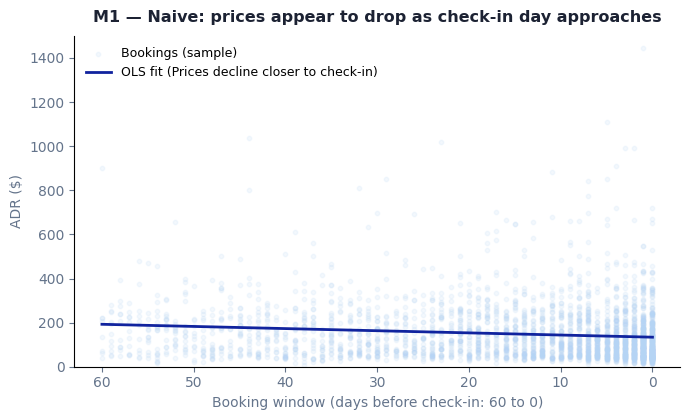

Saved → fig_m1_naive.png


In [ ]:
m1 = smf.ols('adr ~ booking_window', df).fit(cov_type='HC1')
b1   = m1.params['booking_window']
lo1, hi1 = m1.conf_int().loc['booking_window']
p1   = m1.pvalues['booking_window']
span1 = 60 * b1 / mean_adr * 100

print("M1 — Naive OLS")
print(f"  β = ${b1:.3f} per +1 day of booking window")
print(f"  95% CI: [{lo1:.3f}, {hi1:.3f}]")
print(f"  p-value: {p1:.3g}")
print(f"  R²: {m1.rsquared:.4f}")
print(f"  Implied 60→0 day price drop: {-span1:.1f}%")
print()
print("  Interpretation: Looking from left to right (60 days out down to check-in),")
print("  prices appear to steadily drop as the check-in date approaches.")
print("  But this is almost certainly a hotel-mix problem — luxury hotels get booked")
print("  further out AND charge more. We haven't controlled for anything yet.")

sample = df.sample(n=min(3000, len(df)), random_state=42)

fig, ax = plt.subplots(figsize=(7, 4.3))
ax.scatter(sample['booking_window'], sample['adr'],
           alpha=0.15, s=10, color=LIGHT, label='Bookings (sample)')

x_line = np.linspace(df['booking_window'].min(), df['booking_window'].max(), 200)
y_line = m1.params['Intercept'] + b1 * x_line

# Configure visual limits and reverse axis to count down from 60 to 0
ax.invert_xaxis()
ax.set_ylim(0, 1500)  # Caps Y-axis at $1,500 to pull OLS line out of the bottom margin

# Update plot line label to match the 60 -> 0 countdown direction
ax.plot(x_line, y_line, color=NAVY, lw=2, label='OLS fit (Prices decline closer to check-in)')

ax.set_xlabel('Booking window (days before check-in: 60 to 0)', fontsize=10, color=MUT)
ax.set_ylabel('ADR ($)', fontsize=10, color=MUT)
ax.set_title('M1 — Naive: prices appear to drop as check-in day approaches',
             fontsize=11.5, fontweight='bold', color=INK, pad=10)
ax.legend(frameon=False, fontsize=9)

for s in ['top', 'right']:
    ax.spines[s].set_visible(False)
ax.tick_params(colors=MUT)

plt.tight_layout()
plt.savefig('fig_m1_naive.png', dpi=150)
plt.show()
print("Saved → fig_m1_naive.png")

#### Model 2: OLS with Observable Controls

M2 — OLS with observable controls (star rating, chain, weekend, LOS, city, month)
  β = $0.423 per +1 day of booking window
  95% CI: [0.359, 0.487]
  p-value: 1.89e-38
  R²: 0.4070
  Implied 0→60 day price swing: 17.1%

  Chain hotel premium: $6.80
  Star rating premium: $66.74 per star
  Weekend premium:     $23.34

  Interpretation: Once we hold hotel quality, chain status, and season
  constant, the booking_window effect shrinks noticeably. But we're still
  mixing different hotels together — M3 will go further.


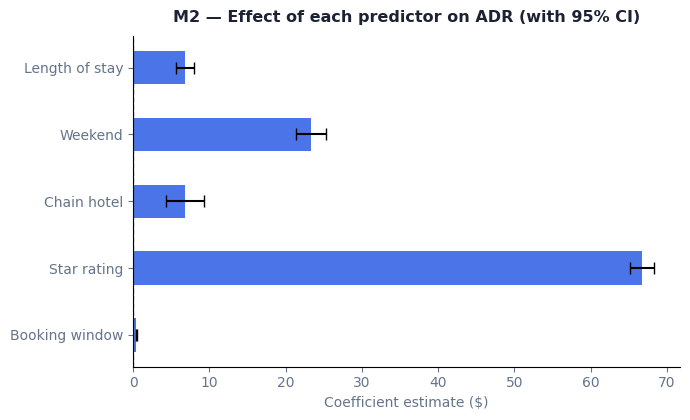

Saved → fig_m2_coefficients.png


In [ ]:
df['checkin_month_cat'] = df['month'].astype('category')

# Create dummy variables for month and city_name to avoid PatsyError issues
month_dummies = pd.get_dummies(df['checkin_month_cat'], prefix='month', drop_first=True)
city_dummies = pd.get_dummies(df['city_name'], prefix='city', drop_first=True)

# Concatenate dummy variables to the dataframe
df_model = pd.concat([df.copy(), month_dummies, city_dummies], axis=1)

# Construct the formula string with the new dummy variable names
month_formula_part = ' + '.join(month_dummies.columns.tolist())
city_formula_part = ' + '.join(city_dummies.columns.tolist())

formula_str = (
    f'adr ~ booking_window + star_rating + chain + weekend + los + '
    f'{city_formula_part} + {month_formula_part}'
)

m2 = smf.ols(formula_str, data=df_model).fit(cov_type='HC1')

b2   = m2.params['booking_window']
lo2, hi2 = m2.conf_int().loc['booking_window']
p2   = m2.pvalues['booking_window']
span2 = 60 * b2 / mean_adr * 100

print("M2 — OLS with observable controls (star rating, chain, weekend, LOS, city, month)")
print(f"  β = ${b2:.3f} per +1 day of booking window")
print(f"  95% CI: [{lo2:.3f}, {hi2:.3f}]")
print(f"  p-value: {p2:.3g}")
print(f"  R²: {m2.rsquared:.4f}")
print(f"  Implied 0→60 day price swing: {span2:.1f}%")
print()
print(f"  Chain hotel premium: ${m2.params['chain']:.2f}")
print(f"  Star rating premium: ${m2.params['star_rating']:.2f} per star")
print(f"  Weekend premium:     ${m2.params['weekend']:.2f}")
print()
print("  Interpretation: Once we hold hotel quality, chain status, and season")
print("  constant, the booking_window effect shrinks noticeably. But we're still")
print("  mixing different hotels together — M3 will go further.")

coef_vars = ['booking_window', 'star_rating', 'chain', 'weekend', 'los']
coef_labels = ['Booking window', 'Star rating', 'Chain hotel', 'Weekend', 'Length of stay']

coefs = [m2.params[v] for v in coef_vars]
ci    = m2.conf_int().loc[coef_vars]
errs  = [(c - ci.loc[v, 0], ci.loc[v, 1] - c) for v, c in zip(coef_vars, coefs)]
lo_errs = [e[0] for e in errs]
hi_errs = [e[1] for e in errs]

colors_coef = [MAGENTA if c < 0 else BLUE for c in coefs]

fig, ax = plt.subplots(figsize=(7, 4.3))
y_pos = range(len(coef_labels))
ax.barh(list(y_pos), coefs, xerr=[lo_errs, hi_errs],
        color=colors_coef, alpha=0.85, capsize=4, height=0.5)
ax.axvline(0, color=MUT, lw=1, ls='--')
ax.set_yticks(list(y_pos))
ax.set_yticklabels(coef_labels, fontsize=10)
ax.set_xlabel('Coefficient estimate ($)', fontsize=10, color=MUT)
ax.set_title('M2 — Effect of each predictor on ADR (with 95% CI)',
             fontsize=11.5, fontweight='bold', color=INK, pad=10)
for s in ['top', 'right']:
    ax.spines[s].set_visible(False)
ax.tick_params(colors=MUT)
plt.tight_layout()
plt.savefig('fig_m2_coefficients.png', dpi=150)
plt.show()
print("Saved → fig_m2_coefficients.png")

#### Model 3: Hotel Fixed Effects

M3 — Hotel fixed effects (within-hotel variation only)
  β = $0.254 per +1 day of booking window
  95% CI: [0.143, 0.364]
  p-value: 6.7e-06
  Implied 0→60 day price swing: 10.3%

  How it works: we subtract each hotel's mean ADR and mean booking_window,
  so we're only using variation WITHIN the same hotel over time.
  The hotel-mix problem is eliminated by construction.

  Interpretation: The effect shrinks further. We're getting closer to a
  clean estimate, but different bookings at the same hotel can still differ
  by room type or length of stay. M4 handles that.


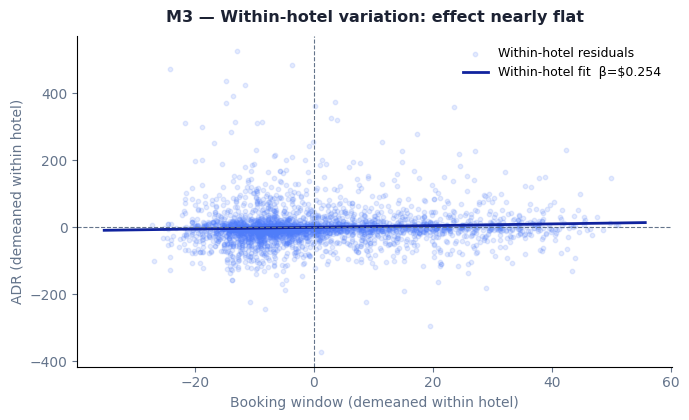

Saved → fig_m3_hotel_fe.png


In [ ]:
d3 = df.copy()
for c in ['adr', 'booking_window']:
    d3[c + '_w'] = d3[c] - d3.groupby('hotel_id')[c].transform('mean')

m3 = smf.ols('adr_w ~ booking_window_w - 1', d3).fit(
    cov_type='cluster', cov_kwds={'groups': d3['hotel_id']}
)

b3   = m3.params['booking_window_w']
lo3, hi3 = m3.conf_int().loc['booking_window_w']
p3   = m3.pvalues['booking_window_w']
span3 = 60 * b3 / mean_adr * 100

print("M3 — Hotel fixed effects (within-hotel variation only)")
print(f"  β = ${b3:.3f} per +1 day of booking window")
print(f"  95% CI: [{lo3:.3f}, {hi3:.3f}]")
print(f"  p-value: {p3:.3g}")
print(f"  Implied 0→60 day price swing: {span3:.1f}%")
print()
print("  How it works: we subtract each hotel's mean ADR and mean booking_window,")
print("  so we're only using variation WITHIN the same hotel over time.")
print("  The hotel-mix problem is eliminated by construction.")
print()
print("  Interpretation: The effect shrinks further. We're getting closer to a")
print("  clean estimate, but different bookings at the same hotel can still differ")
print("  by room type or length of stay. M4 handles that.")

sample3 = d3.sample(n=min(3000, len(d3)), random_state=42)

fig, ax = plt.subplots(figsize=(7, 4.3))
ax.scatter(sample3['booking_window_w'], sample3['adr_w'],
           alpha=0.15, s=10, color=BRIGHT, label='Within-hotel residuals')

x_line3 = np.linspace(d3['booking_window_w'].min(), d3['booking_window_w'].max(), 200)
y_line3  = b3 * x_line3
ax.plot(x_line3, y_line3, color=NAVY, lw=2, label=f'Within-hotel fit  β=${b3:.3f}')

ax.axhline(0, color=MUT, lw=0.8, ls='--')
ax.axvline(0, color=MUT, lw=0.8, ls='--')
ax.set_xlabel('Booking window (demeaned within hotel)', fontsize=10, color=MUT)
ax.set_ylabel('ADR (demeaned within hotel)', fontsize=10, color=MUT)
ax.set_title('M3 — Within-hotel variation: effect nearly flat',
             fontsize=11.5, fontweight='bold', color=INK, pad=10)
ax.legend(frameon=False, fontsize=9)
for s in ['top', 'right']:
    ax.spines[s].set_visible(False)
ax.tick_params(colors=MUT)
plt.tight_layout()
plt.savefig('fig_m3_hotel_fe.png', dpi=150)
plt.show()
print("Saved → fig_m3_hotel_fe.png")

#### Model 4: Stay Fixed Effects

M4 — Stay fixed effects (same hotel × same check-in date, multiple booking windows)
  β = $0.0049 per +1 day of booking window
  95% CI: [-0.0601, 0.0699]
  p-value: 0.882
  Implied 0→60 day price swing: 0.20%
  Sample: 38,221 bookings across 8,526 stay-nights

  How it works: we compare prices for the EXACT SAME room on the EXACT SAME
  night, observed at different booking windows. Nothing else can differ.

  Interpretation: Effect is essentially zero. The urgency message — 'prices
  rise as you wait' — is not supported by this data in aggregate.


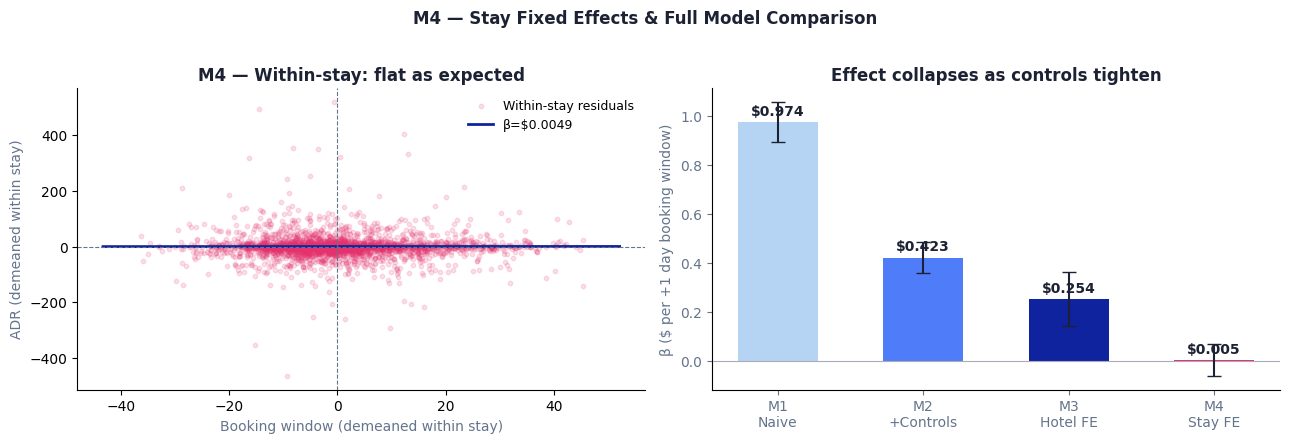

Saved → fig_m4_stay_fe_and_summary.png


In [ ]:
g  = d3.groupby('stay_id')['booking_window'].transform('nunique')
d4 = d3[g >= 2].copy()
for c in ['adr', 'booking_window']:
    d4[c + '_s'] = d4[c] - d4.groupby('stay_id')[c].transform('mean')

m4 = smf.ols('adr_s ~ booking_window_s - 1', d4).fit(
    cov_type='cluster', cov_kwds={'groups': d4['stay_id']}
)

b4   = m4.params['booking_window_s']
lo4, hi4 = m4.conf_int().loc['booking_window_s']
p4   = m4.pvalues['booking_window_s']
span4 = 60 * b4 / mean_adr * 100

print("M4 — Stay fixed effects (same hotel × same check-in date, multiple booking windows)")
print(f"  β = ${b4:.4f} per +1 day of booking window")
print(f"  95% CI: [{lo4:.4f}, {hi4:.4f}]")
print(f"  p-value: {p4:.3g}")
print(f"  Implied 0→60 day price swing: {span4:.2f}%")
print(f"  Sample: {len(d4):,} bookings across {d4['stay_id'].nunique():,} stay-nights")
print()
print("  How it works: we compare prices for the EXACT SAME room on the EXACT SAME")
print("  night, observed at different booking windows. Nothing else can differ.")
print()
print("  Interpretation: Effect is essentially zero. The urgency message — 'prices")
print("  rise as you wait' — is not supported by this data in aggregate.")

sample4 = d4.sample(n=min(3000, len(d4)), random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))

# Left: M4 within-stay scatter
axes[0].scatter(sample4['booking_window_s'], sample4['adr_s'],
                alpha=0.15, s=10, color=MAGENTA, label='Within-stay residuals')
x_line4 = np.linspace(d4['booking_window_s'].min(), d4['booking_window_s'].max(), 200)
axes[0].plot(x_line4, b4 * x_line4, color=NAVY, lw=2, label=f'β=${b4:.4f}')
axes[0].axhline(0, color=MUT, lw=0.8, ls='--')
axes[0].axvline(0, color=MUT, lw=0.8, ls='--')
axes[0].set_xlabel('Booking window (demeaned within stay)', fontsize=10, color=MUT)
axes[0].set_ylabel('ADR (demeaned within stay)', fontsize=10, color=MUT)
axes[0].set_title('M4 — Within-stay: flat as expected', fontweight='bold', color=INK)
axes[0].legend(frameon=False, fontsize=9)
for s in ['top', 'right']:
    axes[0].spines[s].set_visible(False)

# Right: all four betas side by side
all_betas  = [b1, b2, b3, b4]
all_labels = ['M1\nNaive', 'M2\n+Controls', 'M3\nHotel FE', 'M4\nStay FE']
all_colors = [LIGHT, BRIGHT, NAVY, MAGENTA]
all_lo     = [lo1, lo2, lo3, lo4]
all_hi     = [hi1, hi2, hi3, hi4]
yerr       = [[b - l for b, l in zip(all_betas, all_lo)],
              [h - b for b, h in zip(all_betas, all_hi)]]

axes[1].bar(all_labels, all_betas, color=all_colors, width=0.55, zorder=2)
axes[1].errorbar(all_labels, all_betas, yerr=yerr,
                 fmt='none', color=INK, capsize=5, lw=1.5, zorder=3)
for i, (lbl, v) in enumerate(zip(all_labels, all_betas)):
    axes[1].text(i, v + 0.015, f'${v:.3f}',
                 ha='center', va='bottom', fontsize=10, fontweight='bold', color=INK)
axes[1].axhline(0, color='#AAB', lw=0.8)
axes[1].set_ylabel('β ($ per +1 day booking window)', fontsize=10, color=MUT)
axes[1].set_title('Effect collapses as controls tighten', fontweight='bold', color=INK)
for s in ['top', 'right']:
    axes[1].spines[s].set_visible(False)
axes[1].tick_params(colors=MUT)

plt.suptitle('M4 — Stay Fixed Effects & Full Model Comparison',
             fontsize=12, fontweight='bold', color=INK, y=1.02)
plt.tight_layout()
plt.savefig('fig_m4_stay_fe_and_summary.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved → fig_m4_stay_fe_and_summary.png")

### Summary of Model Comparisons

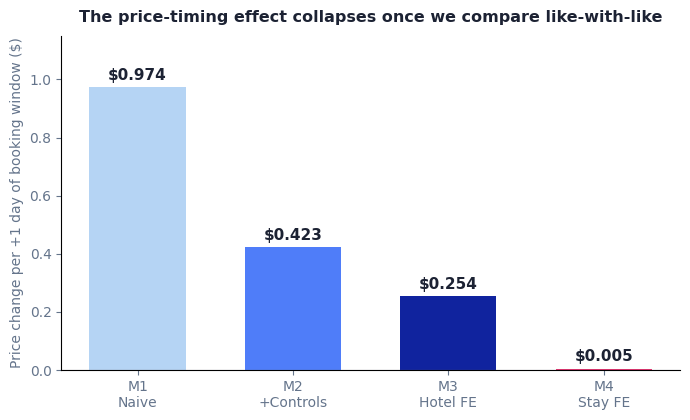

Saved → fig1_model_collapse.png


In [ ]:
all_betas  = [b1, b2, b3, b4]
all_labels = ['M1\nNaive', 'M2\n+Controls', 'M3\nHotel FE', 'M4\nStay FE']
all_colors = [LIGHT, BRIGHT, NAVY, MAGENTA]

fig, ax = plt.subplots(figsize=(7, 4.3))
bars = ax.bar(all_labels, all_betas, color=all_colors, width=0.62)
for b, v in zip(bars, all_betas):
    ax.text(b.get_x() + b.get_width()/2, v + 0.015,
            f'${v:.3f}', ha='center', va='bottom',
            fontsize=11, fontweight='bold', color=INK)

ax.axhline(0, color='#AAB', lw=0.8)
ax.set_ylim(0, max(all_betas) * 1.18)
ax.set_ylabel('Price change per +1 day of booking window ($)', fontsize=10, color=MUT)
ax.set_title('The price-timing effect collapses once we compare like-with-like',
             fontsize=11.5, fontweight='bold', color=INK, pad=10)
for s in ['top', 'right']:
    ax.spines[s].set_visible(False)
ax.tick_params(colors=MUT)
plt.tight_layout()
plt.savefig('fig1_model_collapse.png', dpi=150)
plt.show()
print("Saved → fig1_model_collapse.png")

### Coin-Flip Analysis: Price Direction Towards Check-in

Room-nights analysed: 2,375
Price RISES toward check-in: 47.5%
Price FALLS toward check-in: 52.5%

Note: booking_window shrinks as check-in approaches.
A negative per-stay slope → price went UP as the guest got closer.


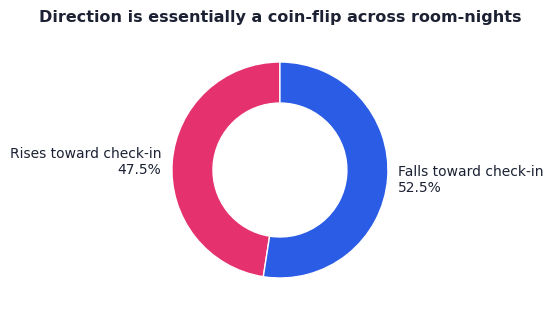

Saved → fig2_coinflip_donut.png


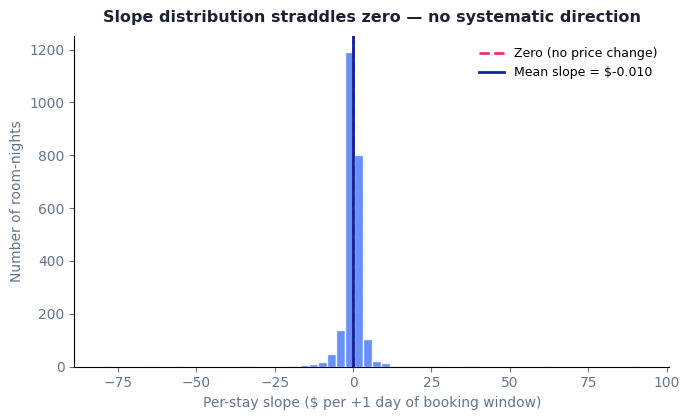

Mean slope: $-0.0103
Median slope: $0.0425
Slopes < 0 (price rising): 47.5%
Slopes > 0 (price falling): 52.5%
Saved → fig2b_slope_distribution.png


In [ ]:
counts = df.groupby('stay_id').size()
multi  = counts[counts >= 5].index
sub    = df[df['stay_id'].isin(multi)].copy()

rows = []
for sid, g in sub.groupby('stay_id'):
    if g['booking_window'].nunique() >= 3 and g['adr'].nunique() >= 2:
        slope = np.polyfit(g['booking_window'], g['adr'], 1)[0]
        rows.append({
            'stay_id': sid,
            'rises':   slope < 0,
            'city':    g['city_name'].iloc[0],
            'star':    g['star_rating'].iloc[0],
            'weekend': g['weekend'].iloc[0],
            'chain':   g['chain_hotel'].astype(str).str.lower().iloc[0]
        })

stay_df = pd.DataFrame(rows)
share   = stay_df['rises'].mean()

print(f"Room-nights analysed: {len(stay_df):,}")
print(f"Price RISES toward check-in: {share*100:.1f}%")
print(f"Price FALLS toward check-in: {(1-share)*100:.1f}%")
print()
print("Note: booking_window shrinks as check-in approaches.")
print("A negative per-stay slope → price went UP as the guest got closer.")

rise = share * 100
fall = 100 - rise

fig, ax = plt.subplots(figsize=(5, 4.3))
ax.pie(
    [rise, fall],
    colors=[MAGENTA, BLUE],
    startangle=90,
    wedgeprops=dict(width=0.38, edgecolor='white'),
    labels=[f'Rises toward check-in\n{rise:.1f}%',
            f'Falls toward check-in\n{fall:.1f}%'],
    textprops=dict(fontsize=10, color=INK)
)
ax.set_title('Direction is essentially a coin-flip across room-nights',
             fontsize=11.5, fontweight='bold', color=INK, pad=10)
plt.tight_layout()
plt.savefig('fig2_coinflip_donut.png', dpi=150)
plt.show()
print("Saved → fig2_coinflip_donut.png")

# recompute slopes as raw values (not just direction)
slope_rows = []
for sid, g in sub.groupby('stay_id'):
    if g['booking_window'].nunique() >= 3 and g['adr'].nunique() >= 2:
        slope = np.polyfit(g['booking_window'], g['adr'], 1)[0]
        slope_rows.append(slope)

slopes_arr = np.array(slope_rows)

fig, ax = plt.subplots(figsize=(7, 4.3))
ax.hist(slopes_arr, bins=60, color=BRIGHT, edgecolor='white', alpha=0.85)
ax.axvline(0, color=MAGENTA, lw=2, ls='--', label='Zero (no price change)')
ax.axvline(slopes_arr.mean(), color=NAVY, lw=2, label=f'Mean slope = ${slopes_arr.mean():.3f}')

ax.set_xlabel('Per-stay slope ($ per +1 day of booking window)', fontsize=10, color=MUT)
ax.set_ylabel('Number of room-nights', fontsize=10, color=MUT)
ax.set_title('Slope distribution straddles zero — no systematic direction',
             fontsize=11.5, fontweight='bold', color=INK, pad=10)
ax.legend(frameon=False, fontsize=9)
for s in ['top', 'right']:
    ax.spines[s].set_visible(False)
ax.tick_params(colors=MUT)
plt.tight_layout()
plt.savefig('fig2b_slope_distribution.png', dpi=150)
plt.show()

pct_neg = (slopes_arr < 0).mean() * 100
print(f"Mean slope: ${slopes_arr.mean():.4f}")
print(f"Median slope: ${np.median(slopes_arr):.4f}")
print(f"Slopes < 0 (price rising): {pct_neg:.1f}%")
print(f"Slopes > 0 (price falling): {100-pct_neg:.1f}%")
print("Saved → fig2b_slope_distribution.png")

### Segment Analysis: Individual and Combined

Segment                  % Rising    vs 50% baseline
----------------------------------------------------
  City D                    57.1%   ▲ above
  Weekend check-in          52.8%   ▲ above
  Chain                     51.7%   ▲ above
  4–5 star                  49.3%   ▼ below
  City A                    45.6%   ▼ below
  Non-Chain                 45.5%   ▼ below
  City E                    44.5%   ▼ below
  Weekday check-in          44.0%   ▼ below
  City B                    43.6%   ▼ below
  Budget (≤2.5★)            40.8%   ▼ below
  City C                    37.0%   ▼ below


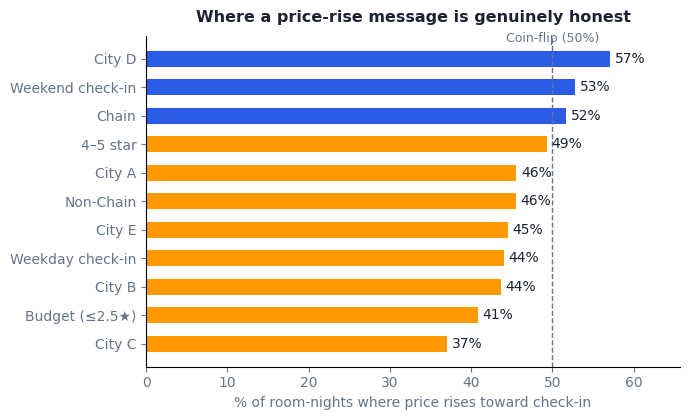

Saved → fig4_segment_targeting.png


In [ ]:
def pct_rising(mask):
    if mask.sum() < 30:
        return None
    return stay_df.loc[mask, 'rises'].mean() * 100

segments = {
    'City A':           pct_rising(stay_df['city'] == 'City_A'),
    'City B':           pct_rising(stay_df['city'] == 'City_B'),
    'City C':           pct_rising(stay_df['city'] == 'City_C'),
    'City D':           pct_rising(stay_df['city'] == 'City_D'),
    'City E':           pct_rising(stay_df['city'] == 'City_E'),
    'Weekend check-in': pct_rising(stay_df['weekend'] == 1),
    'Chain':            pct_rising(stay_df['chain'] == 'chain'),
    'Non-Chain':        pct_rising(stay_df['chain'] == 'non-chain'),
    '4–5 star':         pct_rising(stay_df['star'] >= 4),
    'Weekday check-in': pct_rising(stay_df['weekend'] == 0),
    'Budget (≤2.5★)':   pct_rising(stay_df['star'] <= 2.5)
}
segments = {k: v for k, v in segments.items() if v is not None}

print(f"{'Segment':<22} {'% Rising':>10}   {'vs 50% baseline':>16}")
print("-" * 52)
for k, v in sorted(segments.items(), key=lambda x: -x[1]):
    arrow = '▲ above' if v > 50 else '▼ below'
    print(f"  {k:<20} {v:>9.1f}%   {arrow}")

# Prepare data for plotting using a DataFrame for clarity and easier manipulation
plot_data = pd.DataFrame(segments.items(), columns=['Segment', 'Pct_Rising'])
plot_data = plot_data.sort_values(by='Pct_Rising', ascending=True) # Sort for horizontal bar plot
plot_data['Color'] = plot_data['Pct_Rising'].apply(lambda x: BLUE if x >= 50 else ORANGE)

fig, ax = plt.subplots(figsize=(7, 4.3))
bars = ax.barh(plot_data['Segment'], plot_data['Pct_Rising'], color=plot_data['Color'], height=0.55)

# Add labels to the bars
for b, v in zip(bars, plot_data['Pct_Rising']):
    ax.text(v + 0.6, b.get_y() + b.get_height()/2,
            f'{v:.0f}%', va='center', fontsize=10, color=INK)

ax.axvline(50, color=MUT, ls='--', lw=1)
ax.text(50, len(plot_data['Segment']) - 0.4, 'Coin-flip (50%)',
        color=MUT, fontsize=9, ha='center')
ax.set_xlabel('% of room-nights where price rises toward check-in',
              fontsize=10, color=MUT)
ax.set_title('Where a price-rise message is genuinely honest',
             fontsize=11.5, fontweight='bold', color=INK, pad=10)

# Dynamically set x-axis limit for better scaling
max_pct_rising = plot_data['Pct_Rising'].max()
ax.set_xlim(0, max_pct_rising * 1.15) # Add 15% padding to the max value

for s in ['top', 'right']:
    ax.spines[s].set_visible(False)
ax.tick_params(colors=MUT)
plt.tight_layout()
plt.savefig('fig4_segment_targeting.png', dpi=150)
plt.show()
print("Saved → fig4_segment_targeting.png")

### Identifying Top Combinations for 'Rising Prices'

Let's systematically explore combinations of segments to find those with the highest percentage of rising prices. We'll focus on pairs of segments that have a strong signal.

In [ ]:
import itertools

# Define the individual segment masks and their labels
segment_masks = {
    'City A':           stay_df['city'] == 'City_A',
    'City B':           stay_df['city'] == 'City_B',
    'City C':           stay_df['city'] == 'City_C',
    'City D':           stay_df['city'] == 'City_D',
    'City E':           stay_df['city'] == 'City_E',
    'Weekend check-in': stay_df['weekend'] == 1,
    'Chain':            stay_df['chain'] == 'chain',
    'Non-Chain':        stay_df['chain'] == 'non-chain',
    '4–5 star':         stay_df['star'] >= 4,
    'Weekday check-in': stay_df['weekend'] == 0,
    'Budget (≤2.5★)':   stay_df['star'] <= 2.5
}

combo_signals_2way = {}
combo_signals_3way = {}
min_obs_for_combo = 50 # Minimum observations required for a combo to be considered

# Function to check for mutually exclusive categories
def is_mutually_exclusive(label1, label2):
    # Cities are mutually exclusive
    if ('City' in label1 and 'City' in label2 and label1 != label2): return True
    # Weekend/Weekday check-in are mutually exclusive
    if (('check-in' in label1 and 'check-in' in label2) and (label1 != label2)): return True
    # Star ratings (e.g., 4-5 star and Budget) are generally mutually exclusive
    if (('star' in label1 and 'star' in label2) and (label1 != label2)): return True
    # Chain and Non-Chain are mutually exclusive
    if (('Chain' in label1 and 'Chain' in label2) and (label1 != label2)): return True
    return False

# Generate 2-way combinations
for (label1, mask1), (label2, mask2) in itertools.combinations(segment_masks.items(), 2):
    if is_mutually_exclusive(label1, label2):
        continue

    combined_mask = mask1 & mask2
    num_cases = combined_mask.sum()
    if num_cases >= min_obs_for_combo:
        pct = pct_rising(combined_mask)
        if pct is not None:
            combo_signals_2way[f'{label1} + {label2}'] = {'pct': pct, 'cases': num_cases}

# Generate 3-way combinations
for (label1, mask1), (label2, mask2), (label3, mask3) in itertools.combinations(segment_masks.items(), 3):
    # Check for mutual exclusivity among the three labels
    if (is_mutually_exclusive(label1, label2) or
        is_mutually_exclusive(label1, label3) or
        is_mutually_exclusive(label2, label3)):
        continue

    combined_mask = mask1 & mask2 & mask3
    num_cases = combined_mask.sum()
    if num_cases >= min_obs_for_combo:
        pct = pct_rising(combined_mask)
        if pct is not None:
            combo_signals_3way[f'{label1} + {label2} + {label3}'] = {'pct': pct, 'cases': num_cases}

# --- Display 2-way Combinations ---
print("\n--- 2-Way Combinations ---")
filtered_combos_2way = {k: v for k, v in combo_signals_2way.items() if v['pct'] >= 50}
sorted_combos_2way = sorted(filtered_combos_2way.items(), key=lambda item: item[1]['pct'], reverse=True)

print(f"{'Combination':<45} {'% Rising':>10} {'Cases':>8}   {'vs 50% baseline':>16}")
print("-" * 83)
for k, v in sorted_combos_2way:
    arrow = '▲ above' if v['pct'] > 50 else '✓ 50%'
    print(f"  {k:<43} {v['pct']:>9.1f}% {v['cases']:>8}   {arrow}")

# --- Display 3-way Combinations ---
print("\n--- 3-Way Combinations ---")
filtered_combos_3way = {k: v for k, v in combo_signals_3way.items() if v['pct'] >= 50}
sorted_combos_3way = sorted(filtered_combos_3way.items(), key=lambda item: item[1]['pct'], reverse=True)

print(f"{'Combination':<45} {'% Rising':>10} {'Cases':>8}   {'vs 50% baseline':>16}")
print("-" * 83)
for k, v in sorted_combos_3way:
    arrow = '▲ above' if v['pct'] > 50 else '✓ 50%'
    print(f"  {k:<43} {v['pct']:>9.1f}% {v['cases']:>8}   {arrow}")


--- 2-Way Combinations ---
Combination                                     % Rising    Cases    vs 50% baseline
-----------------------------------------------------------------------------------
  City D + Chain                                   74.5%      165   ▲ above
  City D + Weekend check-in                        71.4%      224   ▲ above
  City D + 4–5 star                                62.9%      350   ▲ above
  Weekend check-in + Chain                         55.1%      336   ▲ above
  Weekend check-in + 4–5 star                      53.5%      488   ▲ above
  City E + Non-Chain                               53.5%      101   ▲ above
  Weekend check-in + Non-Chain                     51.6%      618   ▲ above
  City D + Non-Chain                               51.6%      516   ▲ above
  Chain + 4–5 star                                 50.4%      546   ▲ above
  City D + Weekday check-in                        50.1%      457   ▲ above
  City A + Chain                           

In [ ]:
### Visualizing Combined Segments

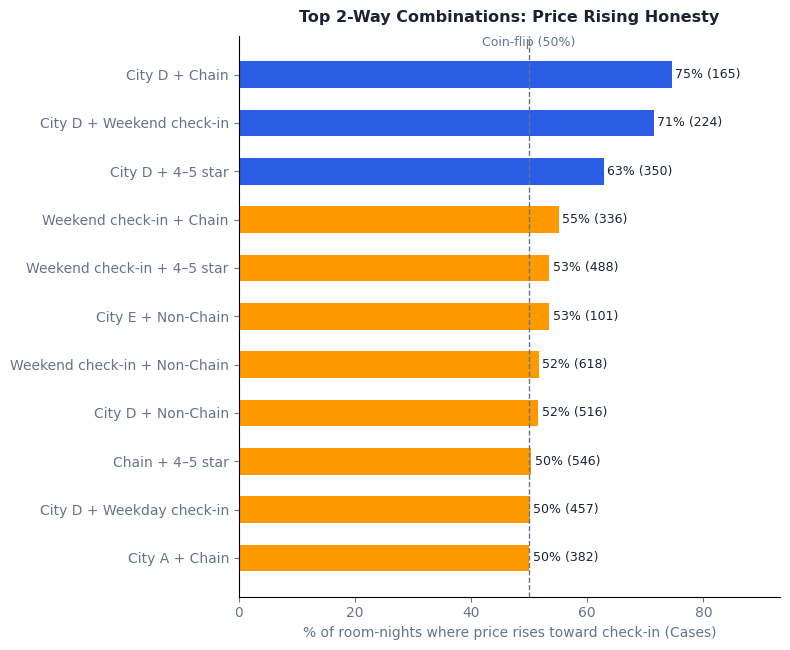

Saved → fig5_2way_combinations.png


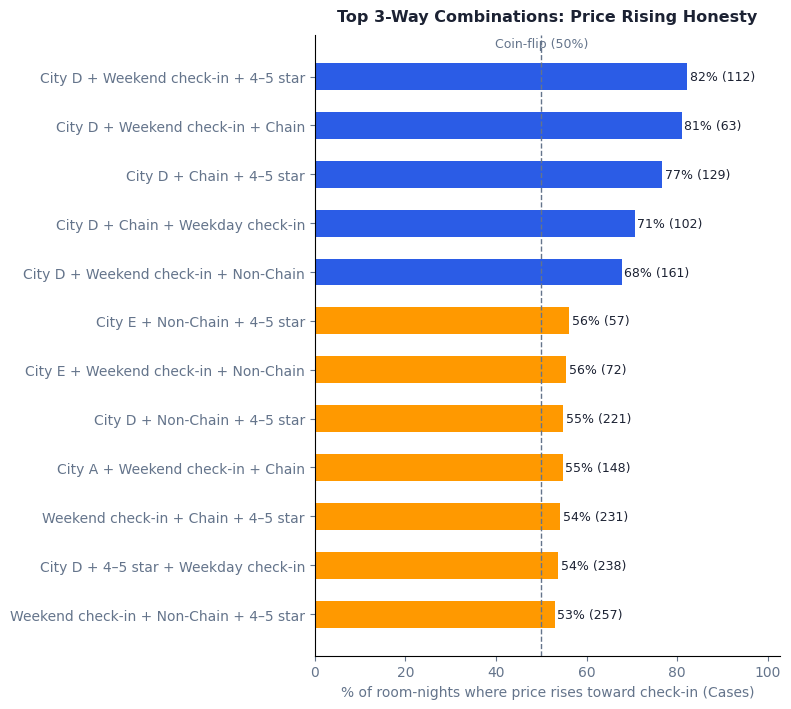

Saved → fig6_3way_combinations.png


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Prepare data for 2-way combinations plot
segments_2w = [k for k, v in sorted_combos_2way]
pct_rising_2w = [v['pct'] for k, v in sorted_combos_2way]
cases_2w = [v['cases'] for k, v in sorted_combos_2way]

# Create DataFrame for 2-way plot data for easier handling
plot_data_2w = pd.DataFrame({
    'Segment': segments_2w,
    'Pct_Rising': pct_rising_2w,
    'Cases': cases_2w
})
plot_data_2w = plot_data_2w.sort_values(by='Pct_Rising', ascending=True) # Sort for horizontal bar plot to display highest at top
plot_data_2w['Color'] = plot_data_2w['Pct_Rising'].apply(lambda x: BLUE if x > 60 else ORANGE)

# Plotting 2-way Combinations
fig_2w, ax_2w = plt.subplots(figsize=(8, len(plot_data_2w) * 0.6))
bars_2w = ax_2w.barh(plot_data_2w['Segment'], plot_data_2w['Pct_Rising'], color=plot_data_2w['Color'], height=0.55)

# Add labels to the bars for 2-way
for b, pct, cases in zip(bars_2w, plot_data_2w['Pct_Rising'], plot_data_2w['Cases']):
    ax_2w.text(pct + 0.6, b.get_y() + b.get_height()/2,
            f'{pct:.0f}% ({cases:,})', va='center', fontsize=9, color=INK)

ax_2w.axvline(50, color=MUT, ls='--', lw=1)
ax_2w.text(50, len(plot_data_2w['Segment']) - 0.4, 'Coin-flip (50%)',
        color=MUT, fontsize=9, ha='center')
ax_2w.set_xlabel('% of room-nights where price rises toward check-in (Cases)',
              fontsize=10, color=MUT)
ax_2w.set_title('Top 2-Way Combinations: Price Rising Honesty',
             fontsize=11.5, fontweight='bold', color=INK, pad=10)
max_pct_rising_2w = plot_data_2w['Pct_Rising'].max()
ax_2w.set_xlim(0, max_pct_rising_2w * 1.25) # Adjust padding for cases label

for s in ['top', 'right']:
    ax_2w.spines[s].set_visible(False)
ax_2w.tick_params(colors=MUT)
plt.tight_layout()
plt.savefig('fig5_2way_combinations.png', dpi=150)
plt.show()
print("Saved → fig5_2way_combinations.png")

# Prepare data for 3-way combinations plot
segments_3w = [k for k, v in sorted_combos_3way]
pct_rising_3w = [v['pct'] for k, v in sorted_combos_3way]
cases_3w = [v['cases'] for k, v in sorted_combos_3way]

# Create DataFrame for 3-way plot data for easier handling
plot_data_3w = pd.DataFrame({
    'Segment': segments_3w,
    'Pct_Rising': pct_rising_3w,
    'Cases': cases_3w
})
plot_data_3w = plot_data_3w.sort_values(by='Pct_Rising', ascending=True) # Sort for horizontal bar plot to display highest at top
plot_data_3w['Color'] = plot_data_3w['Pct_Rising'].apply(lambda x: BLUE if x > 60 else ORANGE)

# Plotting 3-way Combinations
fig_3w, ax_3w = plt.subplots(figsize=(8, len(plot_data_3w) * 0.6))
bars_3w = ax_3w.barh(plot_data_3w['Segment'], plot_data_3w['Pct_Rising'], color=plot_data_3w['Color'], height=0.55)

# Add labels to the bars for 3-way
for b, pct, cases in zip(bars_3w, plot_data_3w['Pct_Rising'], plot_data_3w['Cases']):
    ax_3w.text(pct + 0.6, b.get_y() + b.get_height()/2,
            f'{pct:.0f}% ({cases:,})', va='center', fontsize=9, color=INK)

ax_3w.axvline(50, color=MUT, ls='--', lw=1)
ax_3w.text(50, len(plot_data_3w['Segment']) - 0.4, 'Coin-flip (50%)',
        color=MUT, fontsize=9, ha='center')
ax_3w.set_xlabel('% of room-nights where price rises toward check-in (Cases)',
              fontsize=10, color=MUT)
ax_3w.set_title('Top 3-Way Combinations: Price Rising Honesty',
             fontsize=11.5, fontweight='bold', color=INK, pad=10)
max_pct_rising_3w = plot_data_3w['Pct_Rising'].max()
ax_3w.set_xlim(0, max_pct_rising_3w * 1.25) # Adjust padding for cases label

for s in ['top', 'right']:
    ax_3w.spines[s].set_visible(False)
ax_3w.tick_params(colors=MUT)
plt.tight_layout()
plt.savefig('fig6_3way_combinations.png', dpi=150)
plt.show()
print("Saved → fig6_3way_combinations.png")

In [ ]:
print("=" * 70)
print(f"{'ANALYSIS COMPLETE — KEY FINDINGS':^70}")
print("=" * 70)

print(f"\n{'Overall Metrics':<30}")
print(f"{'-' * 30}")
print(f"Mean ADR across dataset:       ${mean_adr:.2f}")
print(f"Room-nights analyzed:          {len(stay_df):,}")
print(f"Price RISES toward check-in:   {share*100:.1f}%")
print(f"Price FALLS/FLAT:              {(1-share)*100:.1f}%")

print(f"\n{'Regression Analysis: Booking Window Effect on ADR':<60}")
print(f"{'-' * 60}")
print(f"{'Model':<15} {'Beta ($/day)':>15} {'p-value':>10} {'60-day Swing':>15}")
print(f"{'M1 Naive:':<15} {b1:>15.3f} {p1:>10.3g} {span1:>15.1f}%")
print(f"{'M2 +Controls:':<15} {b2:>15.3f} {p2:>10.3g} {span2:>15.1f}%")
print(f"{'M3 Hotel FE:':<15} {b3:>15.3f} {p3:>10.3g} {span3:>15.1f}%")
print(f"{'M4 Stay FE:':<15} {b4:>15.4f} {p4:>10.3g} {span4:>15.2f}%  ← Cleanest Estimate")

print(f"\n{'Segments with >50% Price Rise (Individual)':<70}")
print(f"{'-' * 70}")
print(f"{'Segment':<45} {'% Rising':>10}")
for k, v in sorted(segments.items(), key=lambda x: -x[1]):
    if v is not None and v > 50:
        print(f"  {k:<43} {v:>9.1f}%")

print(f"\n{'Top 2-Way Combinations (>50% Price Rise)':<70}")
print(f"{'-' * 70}")
print(f"{'Combination':<45} {'% Rising':>10} {'Cases':>8}")
for k, v in sorted_combos_2way:
    if v['pct'] >= 50:
        print(f"  {k:<43} {v['pct']:>9.1f}% {v['cases']:>8}")

print(f"\n{'Top 3-Way Combinations (>50% Price Rise)':<70}")
print(f"{'-' * 70}")
print(f"{'Combination':<45} {'% Rising':>10} {'Cases':>8}")
for k, v in sorted_combos_3way:
    if v['pct'] >= 50:
        print(f"  {k:<43} {v['pct']:>9.1f}% {v['cases']:>8}")

print(f"\n{'Generated Figures':<30}")
print(f"{'-' * 30}")
all_figures = [
    'fig1_model_collapse.png',
    'fig2_coinflip_donut.png',
    'fig2b_slope_distribution.png',
    'fig4_segment_targeting.png',
    'fig5_2way_combinations.png',
    'fig6_3way_combinations.png',
    'fig_m1_naive.png',
    'fig_m2_coefficients.png',
    'fig_m3_hotel_fe.png',
    'fig_m4_stay_fe_and_summary.png'
]
for f in sorted(all_figures):
    print(f"  - {f}")

                   ANALYSIS COMPLETE — KEY FINDINGS                   

Overall Metrics               
------------------------------
Mean ADR across dataset:       $148.09
Room-nights analyzed:          2,375
Price RISES toward check-in:   47.5%
Price FALLS/FLAT:              52.5%

Regression Analysis: Booking Window Effect on ADR           
------------------------------------------------------------
Model              Beta ($/day)    p-value    60-day Swing
M1 Naive:                 0.974  2.24e-121            39.5%
M2 +Controls:             0.423   1.89e-38            17.1%
M3 Hotel FE:              0.254    6.7e-06            10.3%
M4 Stay FE:              0.0049      0.882            0.20%  ← Cleanest Estimate

Segments with >50% Price Rise (Individual)                            
----------------------------------------------------------------------
Segment                                         % Rising
  City D                                           57.1%
  Weekend check-

### Regression Analysis: Booking Window Effect on ADR